# Day 1


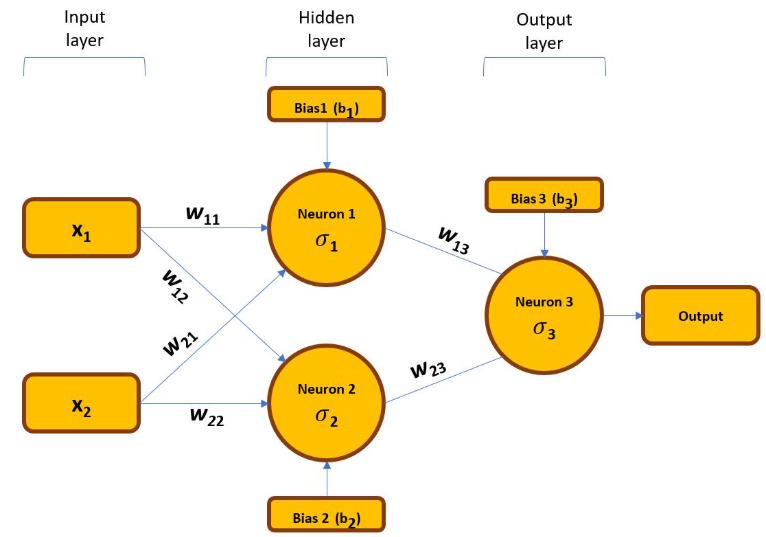

একটি সাধারণ neuron-এর mathematical equation:





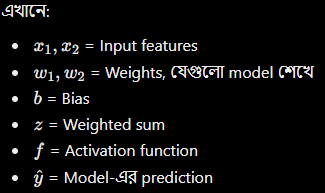

In [1]:

# Day 1: A simple artificial neuron

# Input feature
study_hours = 5.0

# Model parameters (manually assigned for now)
weight = 10.0
bias = 5.0

# Forward propagation
z = study_hours * weight + bias

# Prediction
prediction = z

print("Study Hours:", study_hours)
print("Weighted Sum:", z)
print("Predicted Score:", prediction)


Study Hours: 5.0
Weighted Sum: 55.0
Predicted Score: 55.0


### Day 2 — NumPy দিয়ে নিজের প্রথম Neuron তৈরি
লক্ষ্য: PyTorch ব্যবহার করার আগে বোঝা, একটি ANN-এর neuron আসলে কীভাবে হিসাব করে।

1. আজকের মূল ধারণা:
একটি neuron input নিয়ে weight দিয়ে গুণ করে, bias যোগ করে এবং prediction তৈরি করে।

####                                      z=wx+b


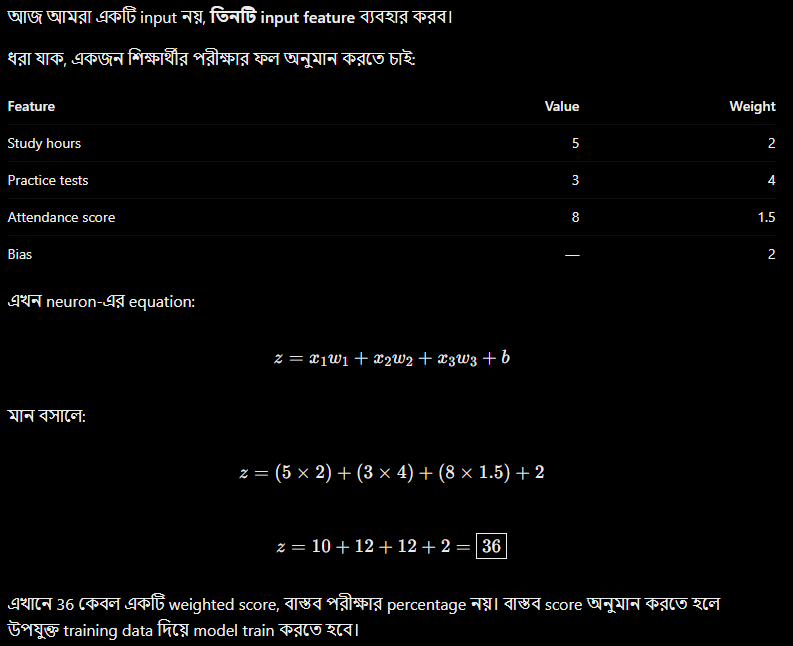

### NumPy দিয়ে neuron তৈরি :

In [2]:

import numpy as np

# Input features
x = np.array([5.0, 3.0, 8.0])

# Weights
w = np.array([2.0, 4.0, 1.5])

# Bias
b = 2.0

# Weighted sum (forward propagation)
z = np.dot(x, w) + b

print("Input:", x)
print("Weights:", w)
print("Weighted sum:", z)


Input: [5. 3. 8.]
Weights: [2.  4.  1.5]
Weighted sum: 36.0


### একই হিসাব PyTorch দিয়ে:

In [ ]:

import torch

# Input tensor
x = torch.tensor([5.0, 3.0, 8.0])

# Weight tensor
w = torch.tensor([2.0, 4.0, 1.5])

# Bias tensor
b = torch.tensor(2.0)

# Forward computation
z = torch.dot(x, w) + b

print("Weighted sum:", z.item())

#z.item() tensor-এর একটি single numerical value-কে সাধারণ Python number হিসেবে দেয়।

Weighted sum: 36.0


### Day 3 — Matrix-Based Forward Propagation

একটি neuron থেকে একাধিক neuron :

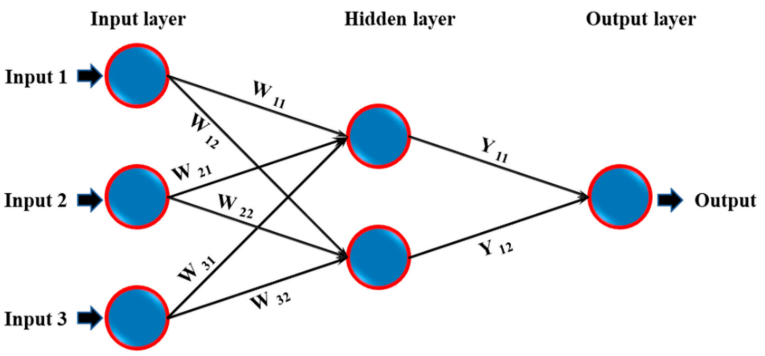

আজকের network:
- Input layer: 2টি feature
- Hidden layer: 3টি neuron
- Output: 1টি neuron

#### Matrix দিয়ে mathematics:
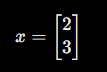
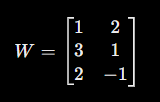
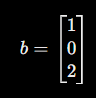
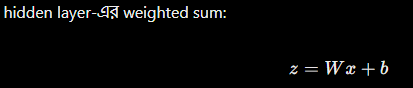
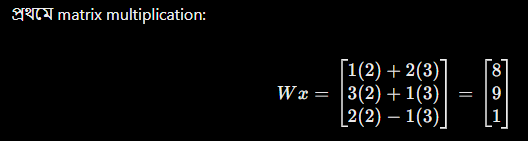
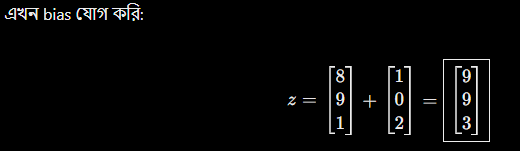




#### Activation function — ReLU:
Neural network সাধারণত weighted sum-এর পরে activation function ব্যবহার করে।

ReLU-এর formula: 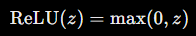
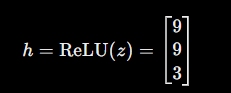


#### NumPy দিয়ে পুরো hidden layer তৈরি

W @ x — matrix multiplication করে।



+ b — প্রতিটি neuron-এর bias যোগ করে।



np.maximum(0, z) — ReLU activation প্রয়োগ করে।



h — পরবর্তী layer-এ পাঠানোর জন্য hidden layer-এর output।

In [6]:

import numpy as np

# Two input features
x = np.array([[2.0],[3.0]])

# Three neurons, each with two weights
W = np.array([
    [1.0,  2.0],
    [3.0,  1.0],
    [2.0, -1.0]
])

# One bias for each neuron
b = np.array([[1.0],
              [0.0],
              [2.0]])

# Forward propagation
z = W @ x + b

# ReLU activation
h = np.maximum(0, z)

print("Weighted sums:\n", z)
print("Hidden layer output:\n", h)


Weighted sums:
 [[9.]
 [9.]
 [3.]]
Hidden layer output:
 [[9.]
 [9.]
 [3.]]


#### PyTorch দিয়ে একই কাজ:

In [2]:

import torch
import torch.nn as nn

# 1 sample, 2 input features
x = torch.tensor([[2.0, 3.0]])

# 2 input features -> 3 neurons
layer = nn.Linear(2, 3)

with torch.no_grad():
    layer.weight.copy_(torch.tensor([
        [1.0,  2.0],
        [3.0,  1.0],
        [2.0, -1.0]
    ]))
    layer.bias.copy_(torch.tensor([1.0, 0.0, 2.0]))

# Forward propagation
z = layer(x)

# ReLU activation
h = torch.relu(z)

print("Input shape:", x.shape)
print("Weighted sums:\n", z)
print("Hidden output:\n", h)


Input shape: torch.Size([1, 2])
Weighted sums:
 tensor([[9., 9., 3.]], grad_fn=<AddmmBackward0>)
Hidden output:
 tensor([[9., 9., 3.]], grad_fn=<ReluBackward0>)
